# შუალედური გამოცდა

## მაღაზიების მდებარეობის ანალიზი  (Analysis of Store Locations)

In [130]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from geopy.geocoders import Nominatim
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import classification_report, confusion_matrix, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [103]:
import warnings
warnings.filterwarnings("ignore")

`datasets/retailer_data/` - აქ არის მონაცემები, რომლებიც ამ დავალებებისთვის დაგჭირდებათ (`Data_1`, `Data_2`, `Sales_1`).

თქვენ გაქვთ `Data_1` მონაცემთა ნაკრები, სადაც თითოეული ჩანაწერი შეესაბამება მაღაზიას სხვადასხვა სასურსათო საცალო ვაჭრობიდან.

In [104]:
# მონაცემების წაკითხვა
df_data_1 = pd.read_csv("../../datasets/retailer_data/Data_1.csv")
df_data_2 = pd.read_csv("../../datasets/retailer_data/Data_2.csv")
df_sales_1 = pd.read_csv("../../datasets/retailer_data/Sales_1.csv")

In [105]:
df_data_1.head()

,Store_ID,Region_ID,Region_Name,Region_Population,Urbanization,Coastal,Region_Area_km2,CNTR_ID,Latitude,Longitude,Retailer,Sales_Area,Location_Type,Parking_Bays
0,8315,FRF12,NaN,0,Intermediate,No,9.0,FR,47.579188,7.516887,Retailer A,336.5,Stand Alone,118
1,541,DEA56,"Witten, Stadt",96565,Urban,No,72.7,DE,51.427850,7.331402,Retailer A,302.8,Stand Alone,130
2,11018,PL227,Żory,62243,Urban,No,65.0,PL,50.036695,18.692633,Retailer B,NaN,Retail Park,47
3,15508,FRI14,NaN,0,Rural,No,10.9,FR,44.487302,0.908630,Retailer B,1111.4,Retail Park,82
4,338,DEA34,"Bocholt, Stadt",71036,Urban,No,119.2,DE,51.852795,6.600894,Retailer A,1895.5,Retail Park,146


In [106]:
df_data_2.head()

,Store_ID,Region_ID,Region_Name,Region_Population,Urbanization,Coastal,Region_Area_km2,CNTR_ID,Latitude,Longitude,Sales_Area,Location_Type,Parking_Bays
0,4600,DE149,"Pfullendorf, Stadt",13287,Intermediate,No,91.0,DE,47.918430,9.257313,1282.7,Retail Park,31
1,17599,PL926,Wiskitki,9870,Rural,No,149.6,PL,52.081424,20.347121,408.6,Stand Alone,113
2,17874,BE323,Quaregnon,19043,Urban,No,11.4,BE,50.437579,3.858041,1201.3,Stand Alone,194
3,8343,FRK25,NaN,0,Intermediate,No,24.2,FR,45.541513,4.181811,325.5,Stand Alone,137
4,1704,DEA2C,"Sankt Augustin, Stadt",55873,Urban,No,34.1,DE,50.771074,7.189527,1949.4,Stand Alone,165


In [107]:
df_sales_1.head()

,Store_ID,Sales
0,0,14249
1,2,4987
2,5,7319
3,6,4159
4,11,10092


### 1. პირველადი შთაბეჭდილება (First Impression)
- რა შეგიძლიათ თქვათ მონაცემთა ხარისხზე?  

In [108]:
# შევამოწმოთ რომელ სვეტში რამდენი არასრული მონაცემი გვაქვს (None)
print("Missing values in Data 1:")
print(df_data_1.isna().sum())
print("--------------------------")

print("\nMissing values in Data 2:")
print(df_data_2.isna().sum())
print("--------------------------")

print("\nMissing values in Sales 1:")
print(df_sales_1.isna().sum())
print("--------------------------")

Missing values in Data 1:
Store_ID                0
Region_ID               0
Region_Name          4940
Region_Population       0
Urbanization            0
Coastal                14
Region_Area_km2         0
CNTR_ID                 0
Latitude                0
Longitude               0
Retailer                0
Sales_Area            716
Location_Type           0
Parking_Bays            0
dtype: int64
--------------------------

Missing values in Data 2:
Store_ID               0
Region_ID              0
Region_Name          549
Region_Population      0
Urbanization           0
Coastal                1
Region_Area_km2        0
CNTR_ID                0
Latitude               0
Longitude              0
Sales_Area            68
Location_Type          0
Parking_Bays           0
dtype: int64
--------------------------

Missing values in Sales 1:
Store_ID    0
Sales       0
dtype: int64
--------------------------


In [109]:
# შევამოწმოთ რამდენი მონაცემი მეორდება
print("Duplicates in Data 1:", df_data_1.duplicated().sum())
print("Duplicates in Data 2:", df_data_2.duplicated().sum())
print("Duplicates in Sales 1:", df_sales_1.duplicated().sum())

Duplicates in Data 1: 0
Duplicates in Data 2: 0
Duplicates in Sales 1: 0


In [110]:
# შევამოწმოთ მონაცემების ტიპი
print("Data types in Data 1:")
print(df_data_1.dtypes)
print("--------------------------")

print("\nData types in Data 2:")
print(df_data_2.dtypes)
print("--------------------------")

print("\nData types in Sales 1:")
print(df_sales_1.dtypes)
print("--------------------------")

Data types in Data 1:
Store_ID               int64
Region_ID             object
Region_Name           object
Region_Population      int64
Urbanization          object
Coastal               object
Region_Area_km2      float64
CNTR_ID               object
Latitude             float64
Longitude            float64
Retailer              object
Sales_Area           float64
Location_Type         object
Parking_Bays           int64
dtype: object
--------------------------

Data types in Data 2:
Store_ID               int64
Region_ID             object
Region_Name           object
Region_Population      int64
Urbanization          object
Coastal               object
Region_Area_km2      float64
CNTR_ID               object
Latitude             float64
Longitude            float64
Sales_Area           float64
Location_Type         object
Parking_Bays           int64
dtype: object
--------------------------

Data types in Sales 1:
Store_ID    int64
Sales       int64
dtype: object
----------------

In [111]:
# დავაკვირდეთ მონაცემთა დიაპაზონს, უჩვეულო მონაცემები ხომ არ გვაქვს
print("Summary statistics for Data 1:")
pd.DataFrame(df_data_1.describe().round(2))

Summary statistics for Data 1:


,Store_ID,Region_Population,Region_Area_km2,Latitude,Longitude,Sales_Area,Parking_Bays
count,18000.00,18000.00,18000.00,18000.00,18000.00,17284.00,18000.00
mean,9991.41,62664.94,74.45,48.02,6.15,1046.52,102.06
std,5774.11,198994.44,129.58,5.00,7.83,565.15,56.52
min,0.00,0.00,0.00,-20.95,-61.54,0.00,5.00
25%,4986.75,0.00,10.80,45.22,1.88,529.92,53.00
50%,9998.00,11203.00,33.10,49.53,6.12,972.95,102.00
75%,14991.25,61523.00,86.82,51.36,10.52,1545.02,151.00
max,19999.00,3613495.00,1751.00,57.42,55.59,2589.50,199.00


In [112]:
print("Summary statistics for Data 2:")
pd.DataFrame(df_data_2.describe().round(2))

Summary statistics for Data 2:


,Store_ID,Region_Population,Region_Area_km2,Latitude,Longitude,Sales_Area,Parking_Bays
count,2000.00,2000.00,2000.00,2000.00,2000.00,1932.00,2000.0
mean,10072.32,62191.95,73.00,48.06,6.09,1038.24,102.4
std,5770.44,161352.04,124.43,4.89,7.85,569.15,56.2
min,3.00,0.00,0.00,28.03,-31.18,0.00,5.0
25%,5163.75,0.00,11.18,45.18,1.82,508.98,54.0
50%,10027.00,11231.50,34.10,49.71,6.11,952.20,104.0
75%,15044.75,63143.25,89.00,51.24,10.30,1552.15,151.0
max,19990.00,1830584.00,1751.00,57.23,23.89,2440.70,199.0


In [113]:
print("Summary statistics for Sales 1:")
pd.DataFrame(df_sales_1.describe().round(2))

Summary statistics for Sales 1:


,Store_ID,Sales
count,3356.00,3356.00
mean,4412.28,8646.01
std,4603.60,3893.61
min,0.00,568.00
25%,1494.75,5081.50
50%,2950.00,8658.00
75%,4470.75,11713.25
max,15057.00,20922.00


- რომელი ნაბიჯების გადადგმაა შესაძლებელი მონაცემთა ხარისხის გასაუმჯობესებლად? 

In [114]:
print(df_data_1.isna().sum())

Store_ID                0
Region_ID               0
Region_Name          4940
Region_Population       0
Urbanization            0
Coastal                14
Region_Area_km2         0
CNTR_ID                 0
Latitude                0
Longitude               0
Retailer                0
Sales_Area            716
Location_Type           0
Parking_Bays            0
dtype: int64


In [115]:
df_data_1.Region_Name.value_counts()

Region_Name
-                     1134
Neu-Ulm, GKSt           30
Lübeck, Hansestadt      30
Iserlohn, Stadt         29
Cottbus, Stadt          29
                      ... 
Bardowick, Flecken       1
Dockendorf               1
Bovenden, Flecken        1
Hohenpolding             1
Barbate                  1
Name: count, Length: 4989, dtype: int64

In [116]:
# NL (Netherlands)-თვის "Region_Name" სვეტი არაა შევსებული
df_data_1[df_data_1["Region_Name"] == "-"]["CNTR_ID"].value_counts()

CNTR_ID
NL    1134
Name: count, dtype: int64

In [117]:
df_data_1["Region_Name"] = df_data_1["Region_Name"].replace("-", np.nan)

In [118]:
def get_region(lat, lon):
    """
    Returns a region name for given latitude and longitude using reverse geocoding.

    Parameters:
        lat (float): Latitude of the location.
        lon (float): Longitude of the location.

    Returns:
        str or None: The name of the region if found, otherwise None.
    """
    try:
        location = geolocator.reverse((lat, lon), language="en", timeout=10)
        return (
            location.raw["address"].get("suburb")
            or location.raw["address"].get("town")
            or location.raw["address"].get("city")
            or location.raw["address"].get("village")
            or location.raw["address"].get("municipality")
        )
    except Exception as e:
        print(f"Error for ({lat}, {lon}): {e}")
        return None

In [119]:
geolocator = Nominatim(user_agent="my-geocoder (tsitsinotefnadze@gmail.com)")
row = df_data_1.loc[0]
get_region(row["Latitude"], row["Longitude"])

'Hésingue'

In [120]:
print(f"Before: Region_Name has {df_data_1["Region_Name"].isna().sum()} missing entries")

df_data_1.loc[df_data_1["Region_Name"].isna(), "Region_Name"] = df_data_1[df_data_1["Region_Name"].isna()].apply(
    lambda row: get_region(row["Latitude"], row["Longitude"]), axis=1
)
print(f"After: Region_Name has {df_data_1["Region_Name"].isna().sum()} missing entries")

Before: Region_Name has 6074 missing entries
After: Region_Name has 1 missing entries


In [15]:
# ეს კოორდინატები მდებარეობს ატლანტის ოკეანეში
df_data_1.loc[df_data_1["Region_Name"].isna(), "Region_Name"] = "Atlantik"

In [480]:
# ვცადოთ Coastal სვეტის მნიშვნელობების შევსება Region_ID-ით
array1 = df_data_1[df_data_1["Coastal"].isna()].Region_ID.unique()
array2 = df_data_1[~df_data_1["Coastal"].isna()].Region_ID.unique()
list(set(array1) & set(array2))

['DE600',
 'DEF03',
 'BE255',
 'DK012',
 'DE80N',
 'DK011',
 'ES213',
 'ES523',
 'ES630',
 'ES212',
 'ES511']

In [481]:
# სვეტ Coastal-ში ჩავანაცვლოთ None მონაცემები Region_ID-ზე დაყრდნობით
df_data_1["Coastal"] = df_data_1.groupby("Region_ID")["Coastal"].transform(lambda x: x.fillna(method="ffill").fillna(method="bfill"))
print(df_data_1["Coastal"].isna().sum())

0


In [482]:
df_data_1["CNTR_ID"].value_counts()

CNTR_ID
DE    5336
FR    4261
ES    2937
PL    2499
NL    1134
BE     721
PT     679
DK     395
LU      38
Name: count, dtype: int64

In [483]:
df_data_1[df_data_1["Region_Population"] == 0]["CNTR_ID"].value_counts()

CNTR_ID
FR    4261
PT     679
DE       3
Name: count, dtype: int64

In [484]:
# შემდეგი რეგიონები დაუსახლებელია
df_data_1[(df_data_1["Region_Population"] == 0) & (df_data_1["CNTR_ID"] == "DE")]

,Store_ID,Region_ID,Region_Name,Region_Population,Urbanization,Coastal,Region_Area_km2,CNTR_ID,Latitude,Longitude,Retailer,Sales_Area,Location_Type,Parking_Bays
13861,14979,DE934,"Gartow, gemfr. Gebiet",0,Rural,No,52.4,DE,52.989201,11.427474,Retailer A,1805.5,Stand Alone,18
16522,14928,DE21K,Gdefr. Geb. (Lkr Rosenheim),0,Rural,No,10.7,DE,47.966098,12.090946,Retailer B,1268.3,Stand Alone,177
16638,14788,DE91B,"Voigtsdahlum, gemfr. Gebiet",0,Rural,No,6.2,DE,52.165651,10.865948,Retailer A,1905.5,Stand Alone,98


In [485]:
df_data_1.loc[(df_data_1["Region_Population"] == 0) & (df_data_1["CNTR_ID"] == "FR"), "Region_Population"] = None
df_data_1.loc[(df_data_1["Region_Population"] == 0) & (df_data_1["CNTR_ID"] == "PT"), "Region_Population"] = None

In [486]:
df_data_1[df_data_1["Region_Area_km2"] == 0]["Region_Name"].unique()

array(['Llocnou de la Corona'], dtype=object)

In [487]:
# მონაცემების შევსება
df_data_1.loc[df_data_1["Region_Area_km2"] == 0, "Region_Area_km2"] = 0.0128

In [488]:
df_data_1["Sales_Area"].value_counts()

Sales_Area
0.0       153
345.0       8
337.8       7
801.5       7
296.3       6
         ... 
162.4       1
2363.5      1
1317.6      1
505.7       1
310.3       1
Name: count, Length: 11022, dtype: int64

In [489]:
df_data_1.loc[df_data_1["Sales_Area"] == 0, "Sales_Area"] = None

In [532]:
# Imputation by mean per retailer
retailer_medians = df_data_1.groupby("Retailer")["Sales_Area"].mean().to_dict()

for retailer in df_data_1["Retailer"].unique():
    df_data_1.loc[
        (df_data_1["Sales_Area"].isna()) & (df_data_1["Retailer"] == retailer),
        "Sales_Area"
    ] = retailer_medians[retailer]

In [208]:
# სვეტ CNTR_ID-ში ჩავანაცვლოთ ქვეყნების შემოკლებული სახელები სრული სახელებით 
country_full_names = {
    "FR": "France",
    "DE": "Germany",
    "PL": "Poland",
    "BE": "Belgium",
    "ES": "Spain",
    "NL": "Netherlands",
    "PT": "Portugal",
    "DK": "Denmark",
    "LU": "Luxembourg"
}

df_data_1["CNTR_ID"] = df_data_1["CNTR_ID"].replace(country_full_names)

In [492]:
# df_data_1.to_csv("datasets/retailer_data/preprocessed_data_1", index=False)

### 2. სიღრმისეული ანალიზი და საცალო ვაჭრობის იდენტიფიკაცია  (Deeper Analysis and Retailer Identification)
- მონაცემების ღრმა ანალიზის შემდეგ, რა შეგიძლიათ თქვათ სხვადასხვა საცალო ბრენდებზე?  

In [493]:
# Count the Number of Stores by Retailer - მაღაზიების რაოდენობა საცალო ვაჭრობის მიხედვით: 
# გაარკვიეთ, რამდენი მაღაზია აქვს თითოეულ საცალო კომპანიას.

retailer_counts = df_data_1["Retailer"].value_counts().reset_index()
print("Number of Stores by Retailer:")
retailer_counts

Number of Stores by Retailer:


,Retailer,count
0,Retailer A,8970
1,Retailer B,6836
2,Retailer C,2194


In [494]:
# Total Sales Area by Retailer - საერთო გაყიდვების ფართობი: 
# გაანგარიშეთ თითოეული საცალო ვაჭრობის საერთო გაყიდვების ფართობი, რათა შეადაროთ მათი მუშაობა.
retailer_sales = df_data_1.groupby("Retailer")["Sales_Area"].sum().round(2).reset_index()
print("\nTotal Sales Area by Retailer:")
retailer_sales


Total Sales Area by Retailer:


,Retailer,Sales_Area
0,Retailer A,10542949.1
1,Retailer B,6847683.3
2,Retailer C,1749540.7


In [495]:
# Retailer Distribution Across Countries - განაწილება ქვეყნებში: 
# გაანალიზეთ, როგორ არის საცალო ვაჭრობები გადანაწილებული სხვადასხვა რეგიონებში.
retailer_region_distribution = df_data_1.groupby(["CNTR_ID", "Retailer"]).size().unstack(fill_value=0).reset_index()
print("\nRetailer Distribution Across Countries:")
retailer_region_distribution


Retailer Distribution Across Countries:


Retailer,CNTR_ID,Retailer A,Retailer B,Retailer C
0,Belgium,402,319,0
1,Denmark,226,169,0
2,France,2250,2011,0
3,Germany,3729,1607,0
4,Luxembourg,23,15,0
5,Netherlands,619,515,0
6,Poland,1360,1139,0
7,Portugal,68,213,398
8,Spain,293,848,1796


In [496]:
# Retailer Presence by Urbanization Level - წარმომადგენლობა ურბანიზაციის დონეების მიხედვით: 
# გამოიკვლიეთ, როგორ არის საცალო ვაჭრობები წარმოდგენილი ურბანიზაციის სხვადასხვა დონეზე.
retailer_urbanization = df_data_1.groupby(["Urbanization", "Retailer"]).size().unstack(fill_value=0).reset_index()
print("\nRetailer Presence by Urbanization Level:")
retailer_urbanization


Retailer Presence by Urbanization Level:


Retailer,Urbanization,Retailer A,Retailer B,Retailer C
0,Intermediate,3595,2688,842
1,Rural,1335,1020,359
2,Urban,4040,3128,993


In [497]:
# Average Store Size by Retailer - მაღაზიის საშუალო ზომა: 
# გაანგარიშეთ საშუალო გაყიდვების ფართობი თითოეული საცალო ვაჭრობისთვის.
average_store_size = df_data_1.groupby("Retailer")["Sales_Area"].mean().reset_index()
print("\nAverage Store Size by Retailer:")
average_store_size


Average Store Size by Retailer:


,Retailer,Sales_Area
0,Retailer A,1175.356644
1,Retailer B,1001.709084
2,Retailer C,797.420556


In [498]:
# Average Region Population by Retailer - რეგიონების საშუალო მოსახლეობა: 
# გამოითვალეთ იმ რეგიონების საშუალო მოსახლეობა, სადაც თითოეული საცალო ვაჭრობა ოპერირებს.
average_region_population = df_data_1.groupby("Retailer")["Region_Population"].mean().reset_index()
print("\nAverage Region Population by Retailer:")
average_region_population


Average Region Population by Retailer:


,Retailer,Region_Population
0,Retailer A,95847.224444
1,Retailer B,84167.302905
2,Retailer C,56911.821269


In [499]:
# Count of Unique Regions per Retailer - უნიკალური რეგიონების რაოდენობა საცალო ვაჭრობის მიხედვით:
# დაადგინეთ, რამდენ უნიკალურ რეგიონში ოპერირებს თითოეული საცალო ვაჭრობა.
unique_regions_per_retailer = df_data_1.groupby("Retailer")["Region_ID"].nunique().reset_index()
print("\nCount of Unique Regions per Retailer:")
unique_regions_per_retailer


Count of Unique Regions per Retailer:


,Retailer,Region_ID
0,Retailer A,714
1,Retailer B,688
2,Retailer C,83


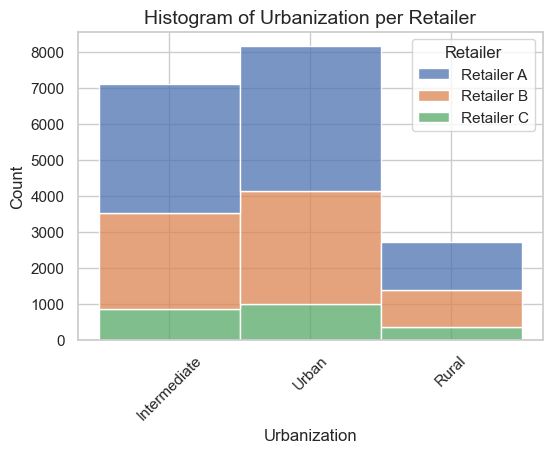

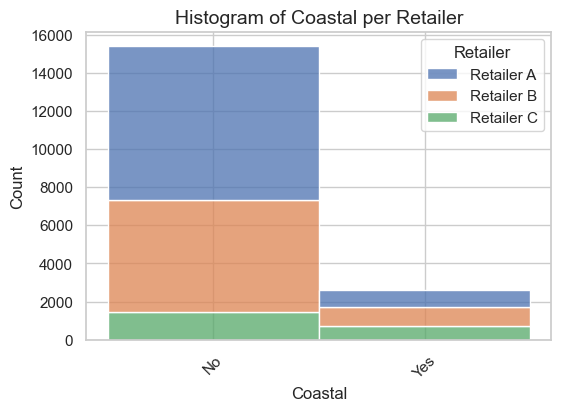

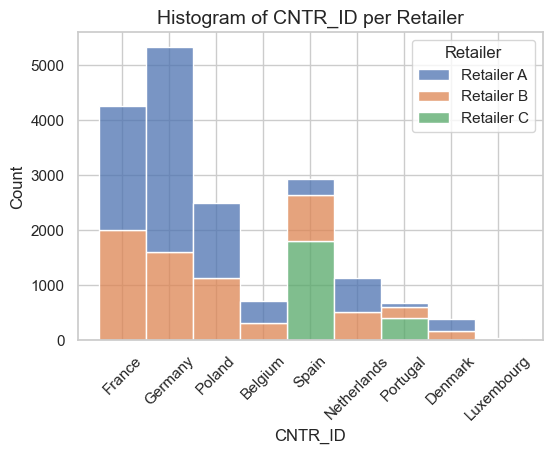

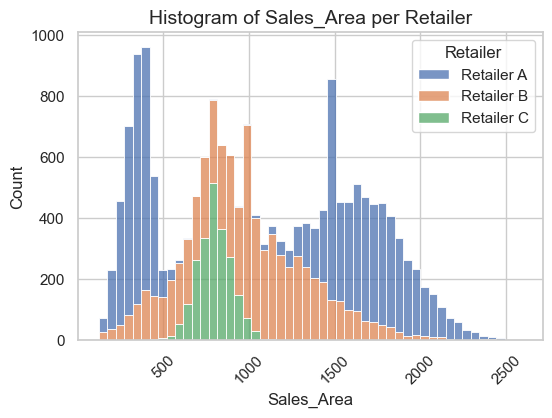

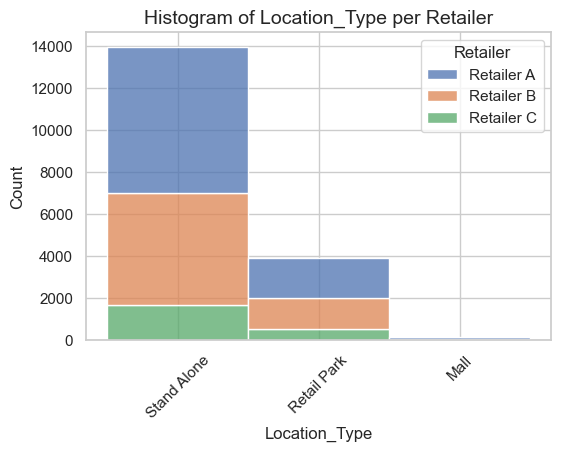

In [500]:
# მონაცემთა განაწილება
for col in ["Urbanization", "Coastal", "CNTR_ID", "Sales_Area", "Location_Type"]:
    sns.set(style="whitegrid")
    plt.figure(figsize=(6, 4))
    sns.histplot(data=df_data_1, x=col, hue="Retailer", multiple="stack", bins=50, kde=False)
    plt.title(f"Histogram of {col} per Retailer", fontsize=14)
    plt.xlabel(col, fontsize=12)
    plt.ylabel("Count", fontsize=12)
    plt.xticks(rotation=45)
    plt.show()

**საცალო ვაჭრობის ანალიზი:**  

- საცალო ვაჭრობა A (Retailer A) არის ბაზრის ლიდერი, ის სარგებლობს მაღაზიების დიდი რაოდენობით, საერთო გაყიდვების ფართობით და ძლიერი წარმომადგენლობით სხვადასხვა რეგიონებსა და ურბანულ ზონებში.
- საცალო ვაჭრობა B (Retailer B) ინარჩუნებს მყარს პოზიციას, მაგრამ მისი ფოკუსი შესაძლოა არ მოიცავდეს ისეთ გეოგრაფიულ არეალს, როგორიც საცალო ვაჭრობა A-ს აქვს.  
- საცალო ვაჭრობა C (Retailer C), რომელიც ყველა მაჩვენებლის მიხედვით მნიშვნელოვნად დაბალ ნიშნულზეა, სავარაუდოდ ნიშურ ბაზარზეა ორიენტირებული. ეს შეიძლება შეზღუდავდეს მის ბაზრის წილს, მაგრამ აძლევდეს შესაძლებლობას, წარმოადგინოს სპეციალიზებული პროდუქტები და მომსახურება.

- თქვენ გეძლევათ დამატებითი მონაცემთა ნაკრები `Data_2`, რომელიც არ შეიცავს საცალო ბრენდის ინფორმაციას, მაგრამ იგივე ტიპის მონაცემებს წარმოადგენს.  
  - გააკეთეთ პროგნოზი საცალო ბრენდი `Data_2`-ისთვის, გამოიყენეთ `Data_1`-ის მონაცემები (`Retailer` სვეტის პროგნოზირება)
  - ახსნეთ თქვენი მეთოდოლოგია.  
  - რა შეიძლება გაუმჯობესდეს ამ პროცესში?  

In [192]:
df_data_1.describe(exclude=np.number)

,Region_ID,Region_Name,Urbanization,Coastal,CNTR_ID,Retailer,Location_Type
count,18000,18000,18000,18000,18000,18000,18000
unique,738,8661,3,2,9,3,3
top,ES511,Guimarães,Urban,No,Germany,Retailer A,Stand Alone
freq,363,47,8161,15385,5336,8970,13995


In [193]:
# Encoding: Trees split on thresholds, numeric order is fine
encoder1 = OrdinalEncoder(categories=[["Rural", "Intermediate", "Urban"]])
df_data_1["Urbanization"] = encoder1.fit_transform(df_data_1[["Urbanization"]])

encoder2 = OrdinalEncoder()
df_data_1["Location_Type"] = encoder2.fit_transform(df_data_1[["Location_Type"]])

df_data_1["Coastal"] = df_data_1["Coastal"].map({"No": 0, "Yes": 1})

In [194]:
df_data_1["Density"] = (df_data_1["Region_Population"] / df_data_1["Region_Area_km2"])
df_data_1["Density"].replace([np.inf, -np.inf], np.nan, inplace=True)

In [195]:
# ცვლადების გამოყოფა (Features & Target)
features = ["Density", "Region_Population", "Urbanization", "Coastal", "Region_Area_km2", "Latitude", "Longitude", "Sales_Area", "Location_Type", "Parking_Bays"]
X = df_data_1[features]
y = df_data_1["Retailer"]

# მონაცემთა გაყოფა (Train-Test Split)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

In [196]:
# Random Forest კლასიფიკატორის გაწვრთნა
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [197]:
# პროგნოზი
y_pred = model.predict(X_val)

In [198]:
# მოდელის ევალუაცია
print(classification_report(y_val, y_pred))

              precision    recall  f1-score   support

  Retailer A       0.83      0.88      0.86      1827
  Retailer B       0.80      0.69      0.74      1353
  Retailer C       0.80      0.95      0.87       420

    accuracy                           0.82      3600
   macro avg       0.81      0.84      0.82      3600
weighted avg       0.82      0.82      0.82      3600



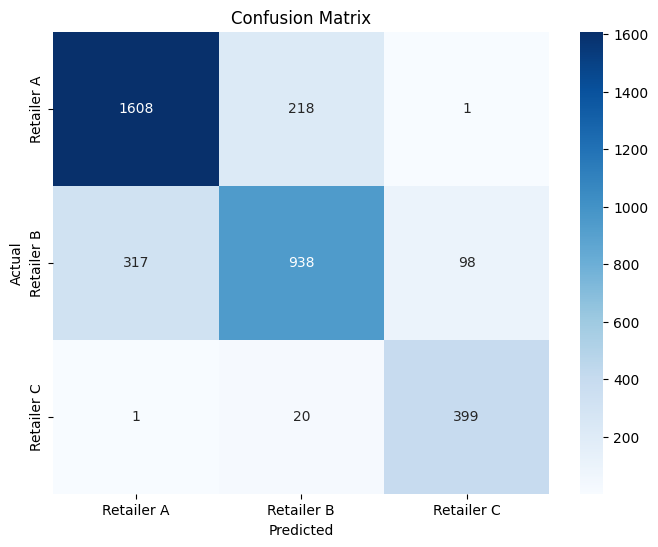

In [199]:
# Confusion matrix
cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=df_data_1["Retailer"].unique(), yticklabels=df_data_1["Retailer"].unique())
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.title("Confusion Matrix")
plt.show()

In [200]:
# Feature importance
importances = model.feature_importances_
feature_importances = pd.DataFrame({"Feature": X.columns, "Importance": importances})
feature_importances = feature_importances.sort_values(by="Importance", ascending=False)
print(feature_importances)

             Feature  Importance
7         Sales_Area    0.451238
5           Latitude    0.171383
6          Longitude    0.128641
9       Parking_Bays    0.066948
4    Region_Area_km2    0.062167
0            Density    0.047822
1  Region_Population    0.044965
2       Urbanization    0.010590
8      Location_Type    0.009928
3            Coastal    0.006317


In [201]:
# მთლიან სიმრავლეზე გავწვრთნათ მოდელი
model.fit(X, y)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [203]:
# Preprocessing for data_2
df_data_2["Coastal"] = df_data_2.groupby("Region_ID")["Coastal"].transform(lambda x: x.fillna(method="ffill").fillna(method="bfill"))

df_data_2.loc[df_data_2["Region_Area_km2"] == 0, "Region_Area_km2"] = 0.0128

df_data_2.loc[(df_data_2["Region_Population"] == 0) & (df_data_2["CNTR_ID"] == "FR"), "Region_Population"] = None
df_data_2.loc[(df_data_2["Region_Population"] == 0) & (df_data_2["CNTR_ID"] == "PT"), "Region_Population"] = None

df_data_2.loc[df_data_2["Sales_Area"] == 0, "Sales_Area"] = None
df_data_2["Sales_Area"].fillna(df_data_2["Sales_Area"].mean(), inplace=True)

df_data_2["CNTR_ID"] = df_data_2["CNTR_ID"].replace(country_full_names)

df_data_2["Density"] = (df_data_2["Region_Population"] / df_data_2["Region_Area_km2"])
df_data_2["Density"].replace([np.inf, -np.inf], np.nan, inplace=True)

df_data_2["Urbanization"] = encoder1.fit_transform(df_data_2[["Urbanization"]])
df_data_2["Location_Type"] = encoder2.fit_transform(df_data_2[["Location_Type"]])
df_data_2["Coastal"] = df_data_2["Coastal"].map({"No": 0, "Yes": 1})

In [204]:
# data_1-ზე გაწვრთნილი მოდელის პროგნოზი data_2-ის მონაცემებზე
retailer_predictions = model.predict(df_data_2[features])
df_data_2["Predicted_Retailer"] = retailer_predictions

In [210]:
df_data_2.head()

,Store_ID,Region_ID,Region_Name,Region_Population,Urbanization,Coastal,Region_Area_km2,CNTR_ID,Latitude,Longitude,Sales_Area,Location_Type,Parking_Bays,Density,Predicted_Retailer
0,4600,DE149,"Pfullendorf, Stadt",13287.0,1.0,0,91.0,Germany,47.918430,9.257313,1282.7,1.0,31,146.010989,Retailer B
1,17599,PL926,Wiskitki,9870.0,0.0,0,149.6,Poland,52.081424,20.347121,408.6,2.0,113,65.975936,Retailer A
2,17874,BE323,Quaregnon,19043.0,2.0,0,11.4,Belgium,50.437579,3.858041,1201.3,2.0,194,1670.438596,Retailer B
3,8343,FRK25,NaN,NaN,1.0,0,24.2,France,45.541513,4.181811,325.5,2.0,137,NaN,Retailer A
4,1704,DEA2C,"Sankt Augustin, Stadt",55873.0,2.0,0,34.1,Germany,50.771074,7.189527,1949.4,2.0,165,1638.504399,Retailer A


In [206]:
df_data_2.Predicted_Retailer.value_counts()

Predicted_Retailer
Retailer A    1034
Retailer B     683
Retailer C     283
Name: count, dtype: int64

### 3. რუკაზე მაღაზიების ადგილმდებარეობების ასახვა
- ქვემოთ მოცემულია მაგალითი, როგორ შეგვიძლია ლონგიტუდისა და ლატიდუდის ინფორმაციის რუკაზე ასახვა. 
- გაანალიზეთ მოცემული მაგალითი.

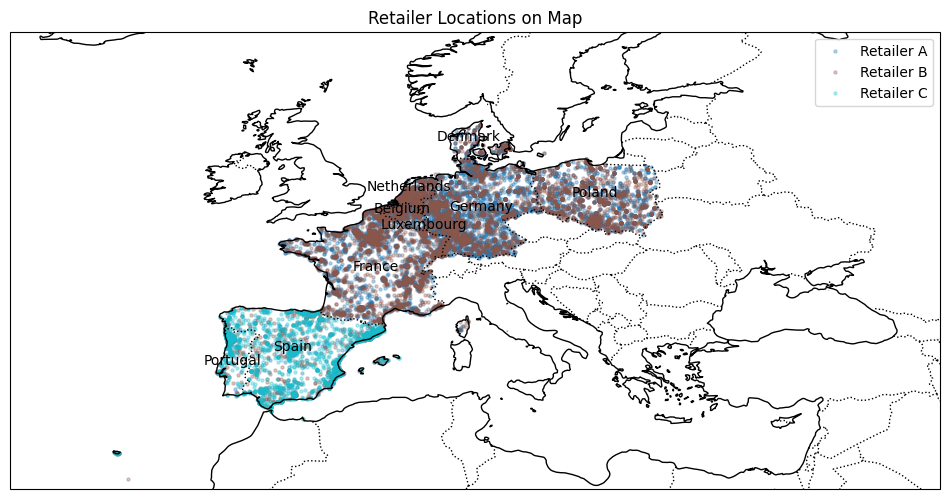

In [211]:
# ქვეყნების ლოკაცია 
country_names = {
    "France": (46.5, 2.5),
    "Germany": (51.0, 10.5),
    "Poland": (52.0, 19.0),
    "Belgium": (50.8, 4.5),
    "Netherlands": (52.5, 5.0),
    "Spain": (40.4168, -3.7038),
    "Portugal": (39.3999, -8.2245),
    "Denmark": (56.2639, 9.5018),
    "Luxembourg": (49.6118, 6.1319),
}

# Cartopy-ის დახმარებით რუკის შექმნა
fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={"projection": ccrs.PlateCarree()})
ax.set_extent([-25, 45, 30, 60])  # boundaries

# ქვეყნის საზღვრების გამოყოფა
ax.add_feature(cfeature.BORDERS, linestyle=":")
ax.add_feature(cfeature.COASTLINE)

# ქვეყნების სახელების რუკაზე დატანა
for country, (lat, lon) in country_names.items():
    plt.text(lon, lat, country, fontsize=10, ha="center", color="black")

# თითოეული Retailer სხვადასხვა ფერით რომ გამოვყოთ
unique_retailers = df_data_1["Retailer"].unique()
colors = plt.cm.get_cmap("tab10", len(unique_retailers))

# თითოეული ლოკაცია განსხვავებული ფერით based on retailer
for i, retailer in enumerate(unique_retailers):
    retailer_data = df_data_1[df_data_1["Retailer"] == retailer]
    ax.scatter(retailer_data["Longitude"].values, retailer_data["Latitude"].values, marker="o", color=colors(i), s=5, label=retailer, alpha=0.3)
plt.title("Retailer Locations on Map")
plt.legend();

### 4. გაყიდვების პროგნოზი  (Sales Prediction)
თქვენ გეძლევათ დამატებითი მონაცემები `Sales_1`, რომელიც შეესაბამება `Data_1`-ს და შეიცავს გაყიდვების მთლიანი შემოსავალს (1000€ წელიწადში) გარკვეული მაღაზიებისთვის საცალო ვაჭრობის A ბრენდიდან გერმანიაში.  
- შექმენით მარტივი გაყიდვების პროგნოზის მოდელი, რომელიც შეძლებს ახალი მაღაზიის გაყიდვების შეფასებას. გამოიყენეთ მოდელი საცალო ვაჭრობის A ბრენდის (Retailer A) მაღაზიებზე გერმანიაში, სადაც გაყიდვების მონაცემები აკლია (`Sales` სვეტის პროგნოზირება).

    - რომელი მახასიათებლები (features) მიგაჩნიათ ყველაზე მნიშვნელოვანად?  
    - არის სხვა მახასიათებლები, რომლებიც შეგვიძლია დავამატოთ?

In [212]:
# ორი dataset-ის შეერთება
merged_df = df_data_1.merge(df_sales_1, on="Store_ID", how="left")

In [213]:
# განვიხილავთ მხოლოდ A ბრენდის მაღაზიებს სადაც Sales სვეტის მონაცემები None არის 
missing_sales_df = merged_df[(merged_df["Retailer"] == "Retailer A") & (merged_df["Sales"].isna())]

In [214]:
# არსებულ ინფორმაციაზე დაყრდნობით გავწვრთნათ მოდელი
known_sales_df = merged_df[merged_df["Sales"].notna()]

In [215]:
# გამოვყოთ features და target
features = ["Region_Population", "Urbanization", "Region_Area_km2", "Latitude", "Longitude", "Sales_Area", "Parking_Bays", "Location_Type"] 
X = known_sales_df[features]
y = known_sales_df["Sales"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [216]:
# რეგრესიის მოდელი
model = RandomForestRegressor()
model.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [217]:
# პროგნოზი
y_pred = model.predict(X_test)

# მოდელის ევალუაცია
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}") # ერთეული - €
print(f"Mean Squared Error (MSE): {mse:.2f}") # ერთეული - €²
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}") # ერთეული - €
print(f"R² Score: {r2:.2f}")

Mean Absolute Error (MAE): 1369.78
Mean Squared Error (MSE): 3314036.05
Root Mean Squared Error (RMSE): 1820.45
R² Score: 0.78


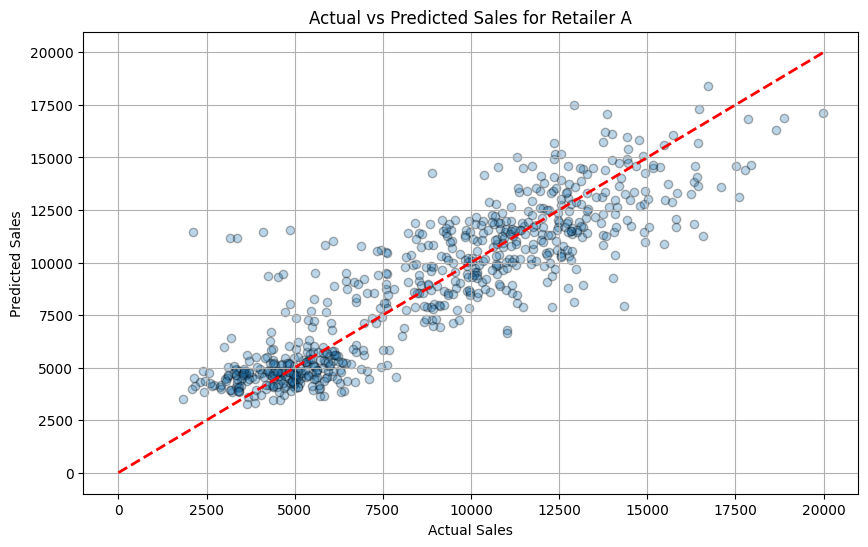

In [220]:
# Actual vs Predicted
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.3, edgecolors="k")
max_value = max(max(y_test), max(y_pred))  # Get the maximum value for the axis limit
plt.plot([0, max_value], [0, max_value], "r--", lw=2)
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales for Retailer A")
plt.grid(True)
plt.show()

In [221]:
# რამდენად მნიშვნელოვანია მახასიათებლები (feature importance)
importances = model.feature_importances_
importance_df = pd.DataFrame({"Feature": X.columns, "Importance": importances})
importance_df = feature_importances.sort_values(by="Importance", ascending=False)
importance_df

,Feature,Importance
7,Sales_Area,0.451238
5,Latitude,0.171383
6,Longitude,0.128641
9,Parking_Bays,0.066948
4,Region_Area_km2,0.062167
0,Density,0.047822
1,Region_Population,0.044965
2,Urbanization,0.010590
8,Location_Type,0.009928
3,Coastal,0.006317


In [222]:
# მთლიან სიმრავლეზე გავწვრთნათ მოდელი
model.fit(X, y)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [223]:
# Data for prediction
X_missing = missing_sales_df[features]

# Add predictions to the missing data DataFrame
missing_sales_df["Sales"] = model.predict(X_missing)

In [224]:
missing_sales_df.head()

,Store_ID,Region_ID,Region_Name,Region_Population,Urbanization,Coastal,Region_Area_km2,CNTR_ID,Latitude,Longitude,Retailer,Sales_Area,Location_Type,Parking_Bays,Density,Sales
0,8315,FRF12,Hésingue,NaN,1.0,0,9.0,France,47.579188,7.516887,Retailer A,336.500000,2.0,118,NaN,4951.04
6,18569,BE310,Villers-la-Ville,10723.0,1.0,0,48.1,Belgium,50.562933,4.525105,Retailer A,1845.500000,2.0,135,222.931393,10996.50
15,13842,PL411,Jastrowie,11592.0,1.0,0,351.8,Poland,53.403048,16.657434,Retailer A,1055.867392,2.0,22,32.950540,7499.27
16,18593,BE251,Oostkamp,23593.0,1.0,0,79.7,Belgium,51.118151,3.228956,Retailer A,212.400000,2.0,125,296.022585,3617.53
19,6609,FRD22,Oissel-sur-Seine,NaN,2.0,0,22.5,France,49.347989,1.073709,Retailer A,1576.000000,1.0,126,NaN,13093.18


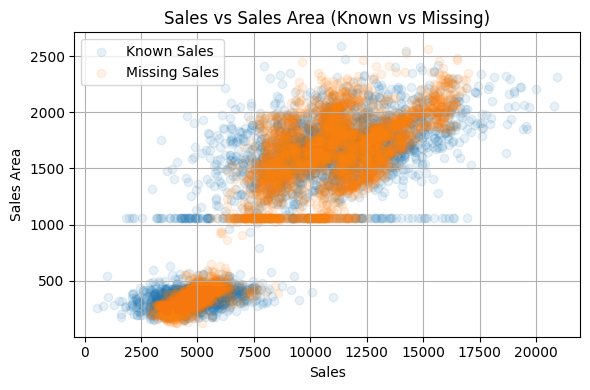

In [227]:
plt.figure(figsize=(6, 4))
plt.scatter(known_sales_df["Sales"], known_sales_df["Sales_Area"], alpha=0.1, label="Known Sales")
plt.scatter(missing_sales_df["Sales"], missing_sales_df["Sales_Area"], alpha=0.1, label="Missing Sales")
plt.xlabel("Sales")
plt.ylabel("Sales Area")
plt.title("Sales vs Sales Area (Known vs Missing)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

ასევე საინტერესო იქნება ისეთი მონაცემების გათვალისწინება როგორიცაა:
- ეკონომიკური მაჩვენებლები: საშუალო შემოსავალი, უმუშევრობის დონე, ინფლაციის დონე რეგიონისთვის

- მარკეტინგი და აქციები 

- რეგიონზე სპეციფიკური მახასიათებლები: ტურისტული აქტივობა

In [228]:
economical_data = {
    "France": {
        "GDP": 44220, 
        "Unemployment_rate": 7.1, 
        "Inflation_rate": 4.5, 
        "Overall_economic_growth": 1.2,
        "Average_income": 31000
    },
    "Germany": {
        "GDP": 51190, 
        "Unemployment_rate": 5.7, 
        "Inflation_rate": 4.3, 
        "Overall_economic_growth": 0.4,
        "Average_income": 45000
    },
    "Poland": {
        "GDP": 19500, 
        "Unemployment_rate": 3.3, 
        "Inflation_rate": 8.8, 
        "Overall_economic_growth": 2.0,
        "Average_income": 15500
    },
    "Belgium": {
        "GDP": 53240, 
        "Unemployment_rate": 5.4, 
        "Inflation_rate": 5.2, 
        "Overall_economic_growth": 1.3,
        "Average_income": 35000
    },
    "Spain": {
        "GDP": 32680, 
        "Unemployment_rate": 12.6, 
        "Inflation_rate": 3.8, 
        "Overall_economic_growth": 1.9,
        "Average_income": 24000
    },
    "Netherlands": {
        "GDP": 57200, 
        "Unemployment_rate": 4.0, 
        "Inflation_rate": 5.8, 
        "Overall_economic_growth": 1.6,
        "Average_income": 48000
    },
    "Portugal": {
        "GDP": 27500, 
        "Unemployment_rate": 6.2, 
        "Inflation_rate": 3.2, 
        "Overall_economic_growth": 2.4,
        "Average_income": 18500
    },
    "Denmark": {
        "GDP": 68200, 
        "Unemployment_rate": 4.7, 
        "Inflation_rate": 2.8, 
        "Overall_economic_growth": 1.7,
        "Average_income": 58000
    },
    "Luxembourg": {
        "GDP": 131000, 
        "Unemployment_rate": 4.8, 
        "Inflation_rate": 3.7, 
        "Overall_economic_growth": 2.5,
        "Average_income": 67000
    }
}